# YSL merFISH Projections: Polar Plots

## Environment Setup

Install software from pip, apt, and Github.  Load modules, configure workspace settings.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Environment Setup: everything now handled inside zmap-tools
#!pip -q install "git+https://github.com/WagnerLabUCSF/zmap-tools.git"
!pip -q install igraph leidenalg zmap-tools

import zmap
import scanpy as sc

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 86.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 71.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.1/102.1 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 176.1/176.1 kB 14.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.5/18.5 MB 95.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 44.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 119.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 376.9/376.9 kB 17.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 74.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 225.0/225

In [ ]:
!pip list

Package                               Version
------------------------------------- ------------------
absl-py                               1.4.0
accelerate                            1.14.0
access                                1.1.10.post3
adjustText                            1.4.0
affine                                2.4.0
aiofiles                              25.1.0
aiohappyeyeballs                      2.7.1
aiohttp                               3.14.1
aiosignal                             1.4.0
aiosqlite                             0.22.1
alabaster                             1.0.0
albucore                              0.0.24
albumentations                        2.0.8
ale-py                                0.12.0
altair                                5.5.0
anndata                               0.12.18
annotated-doc                         0.0.4
annotated-types                       0.7.0
antlr4-python3-runtime                4.9.3
anyio                                 4.14.2
a

In [ ]:
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Load YSL h5ad

In [ ]:
# Load YSL query dataset
base_path='/content/drive/MyDrive/Colab Notebooks/Haley/YSL/'
adata = sc.read(base_path+'YSL-subset_pp_norm_processed.h5ad')
adata

AnnData object with n_obs × n_vars = 4823 × 31859
    obs: 'sample', 'species', 'gene_count', 'tscp_count', 'mread_count', 'bc1_well', 'bc2_well', 'bc3_well', 'bc1_wind', 'bc2_wind', 'bc3_wind', 'n_genes', 'leiden_seed', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'GEP1', 'GEP2', 'GEP3', 'GEP4', 'clusters', 'clusters_uncertainty', 'phi', 'phi_uncertainty', 'phi_folded', 'theta', 'bmp16_expressed', 'bmp2b_expressed', 'bmp16_bmp2b_coexpressed', 'bmp16_bmp7a_coexpressed', 'bmp16_bmp4_coexpressed'
    var: 'gene_id', 'genome', 'n_cells', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'bmp16_expressed_colors', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'n_sig_PCs', 'neighbors', 'pca', 'rank_genes_groups', 'sample_colors', 'umap'
    obsm: 'X_cnmf', 'X_pca', 'X_pca_ref', 'X_umap'
    varm: 'PCs'
    layers: 'raw', 'raw_nolog', 'tpm',

## Plotting merFish projections vs gene expression

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
import scanpy as sc

def pl_scatter_polar(
    adata,
    phi="phi",
    theta="theta",
    color=None,
    cmap="RdBu_r",
    phi_units="degrees",
    sort_order=True,
    random_seed=0,
    mirror=False,
    half=False,
    half_pad=0.12,
    gridlines=True,
    theta_ticks=None,
    phi_ticks=None,
    grid_kwargs=None,
    label_kwargs=None,
    tick_label_kwargs=None,
    spoke_label_kwargs=None,
    show_theta_labels=True,
    show_spoke_labels=True,
    theta_label_side="above",
    theta_label_gap=12,
    theta_label_fmt=None,
    phi_label_fmt=None,
    label_notation="sub",
    frame=False,
    colorbar_pad=0.05,
    colorbar_width=0.03,
    vmin=None,
    vmax=None,
    standard_scale="var",
    layer=None,
    size=25,
    alpha=0.8,
    title=None,
    ax=None,
    show=True,
    tmp_x_col="_zmap_polar_x_tmp_8f2a",
    tmp_y_col="_zmap_polar_y_tmp_8f2a",
    tmp_c_col="_zmap_polar_c_tmp_8f2a",
    **sc_scatter_kwargs,
):
    """sc.pl.scatter with phi/theta drawn in polar coords: theta is the radius from
    center, phi is the angle around it. Layout (phi in degrees, 0 = dorsal):

        phi 0   -> right (+x), dorsal      theta 0   -> center (animal pole)
        phi 90  -> up (+y)                 theta max -> outer rim
        phi 180 -> left (-x)

    Reading expression
    ------------------
    `layer` is the single knob for which layer to color from. We always read the
    values ourselves and hand them to scanpy as a scratch obs column, so a stray
    scanpy-style `layers=` is absorbed into `layer` and use_raw defaults to False
    (that combination is what scanpy errors on). If `layer` is None we read .X.

    Sort order
    ----------
    scanpy always draws low-on-top, so we bake the rendered colors, drop the
    collection, and redraw in our own order. sort_order=True puts high values on
    top; False shuffles with a fixed seed so nothing dominates.

    Notable params
    --------------
    color           gene name or obs column.
    standard_scale  truthy (default "var") z-scores then rescales color to [0, 1];
                    for a single gene this is just per-gene scaling. False to skip.
    half            show only the top half (phi 0-180).
    mirror          also draw points reflected across the x-axis.
    theta_label_*   side / gap / fmt control the ring labels; phi_label_fmt the spokes.
    label_notation  "sub" (default) renders ticks as $\\theta_{30}$ / $\\phi_{90}$;
                    "super" for superscripts. An explicit *_label_fmt overrides it.
    grid_kwargs, label_kwargs, tick_label_kwargs, spoke_label_kwargs
                    styling; label_kwargs hits all gridline labels, the per-type
                    dicts override it.
    frame           draw the box around the plot (default off).
    """
    if phi_units not in ("degrees", "radians"):
        raise ValueError(f"phi_units must be 'degrees' or 'radians', got '{phi_units}'")
    if theta_label_side not in ("above", "below"):
        raise ValueError(f"theta_label_side must be 'above' or 'below', got '{theta_label_side}'")
    if label_notation not in ("sub", "super"):
        raise ValueError(f"label_notation must be 'sub' or 'super', got '{label_notation}'")

    # one knob for layers: fold a stray scanpy-style `layers` into `layer`, never forward it
    if "layers" in sc_scatter_kwargs:
        stray = sc_scatter_kwargs.pop("layers")
        if layer is None:
            layer = stray[-1] if isinstance(stray, (tuple, list)) else stray
    sc_scatter_kwargs.setdefault("use_raw", False)   # we read expression ourselves

    def fmt_tick(value, fmt, default):
        """None -> default(value); callable -> fmt(value); str -> fmt.format(value)."""
        if fmt is None:
            return default(value)
        return fmt(value) if callable(fmt) else fmt.format(value)

    is_categorical = color is not None and color in adata.obs.columns and hasattr(adata.obs[color], "cat")
    use_tmp_color = color is not None and not is_categorical    # read every continuous color ourselves

    tmp_cols = [tmp_x_col, tmp_y_col] + ([tmp_c_col] if use_tmp_color else [])
    for col in tmp_cols:
        if col in adata.obs.columns:
            raise ValueError(f"adata.obs already has a column named '{col}'. Drop it or pass a different tmp col name.")

    saved_cmap = saved_norm = None

    # the try starts before any write to adata.obs so the finally always cleans the
    # scratch columns, even if the color lookup raises (e.g. a misspelled gene).
    try:
        phi_vals = adata.obs[phi].values.copy()
        theta_vals = adata.obs[theta].values
        if phi_units == "degrees":
            phi_vals = np.deg2rad(phi_vals)
        adata.obs[tmp_x_col] = theta_vals * np.cos(phi_vals)
        adata.obs[tmp_y_col] = theta_vals * np.sin(phi_vals)

        color_key = color
        if use_tmp_color:
            if color in adata.obs.columns:
                vals = adata.obs[color].values.astype(float)
            elif color in adata.var_names:
                raw = adata[:, color].layers[layer] if layer is not None else adata[:, color].X
                vals = raw.toarray().flatten() if hasattr(raw, "toarray") else np.asarray(raw).flatten()
            else:
                raise KeyError(f"'{color}' not found in adata.obs or adata.var_names")
            vals = vals.astype(float)

            if standard_scale:                          # z-score, then squeeze into [0, 1]
                if vals.std() > 0:
                    vals = (vals - vals.mean()) / vals.std()
                if vals.max() > vals.min():
                    vals = (vals - vals.min()) / (vals.max() - vals.min())
            if vmin is not None:
                vals = np.clip(vals, vmin, None)
            if vmax is not None:
                vals = np.clip(vals, None, vmax)

            adata.obs[tmp_c_col] = vals
            color_key = tmp_c_col

        if cmap is not None:
            sc_scatter_kwargs["color_map"] = cmap
        if theta_ticks is None:
            theta_ticks = [30, 60, 90, 120]
        if phi_ticks is None:
            phi_ticks = list(range(0, 181, 30)) if half else list(range(0, 360, 30))

        own_fig = ax is None
        if own_fig:
            fig, ax = plt.subplots(figsize=(6, 4) if half else (6, 6))
        else:
            fig = ax.figure

        pre_axes = set(fig.axes)
        sc.pl.scatter(adata, x=tmp_x_col, y=tmp_y_col, color=color_key,
                      size=size, alpha=alpha, ax=ax, show=False, **sc_scatter_kwargs)
        for extra in set(fig.axes) - pre_axes:          # drop any colorbar scanpy added; we add our own
            extra.remove()

        # redraw in our own z-order (scanpy ignores sort_order). Bake the rendered
        # RGBA first, grab cmap/norm for the colorbar, then replace the collection.
        if not is_categorical and color is not None:
            col = ax.collections[0]
            scalar = np.array(col.get_array())
            if scalar is not None and len(scalar) > 0:
                saved_cmap, saved_norm = col.get_cmap(), col.norm
                fig.canvas.draw()
                offsets = np.array(col.get_offsets())
                colors = np.array(col.get_facecolors())
                sizes = np.array(col.get_sizes())
                pt_alpha = col.get_alpha()
                n = len(offsets)
                if sort_order:
                    order = np.argsort(scalar, kind="stable")        # high on top
                else:
                    order = np.random.default_rng(random_seed).permutation(n)
                col.remove()
                ax.scatter(offsets[order, 0], offsets[order, 1],
                           c=colors[order] if len(colors) == n else colors,
                           s=sizes[order] if len(sizes) == n else sizes,
                           alpha=pt_alpha, edgecolors="none", zorder=3)

        if mirror:
            col = ax.collections[0]
            sizes = col.get_sizes()
            ax.scatter(adata.obs[tmp_x_col].values, -adata.obs[tmp_y_col].values,
                       c=col.get_facecolors(), s=sizes if len(sizes) > 1 else sizes[0],
                       alpha=col.get_alpha())

        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.set_aspect("equal")
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_frame_on(frame)

        if gridlines:
            grid = {"color": "black", "linewidth": 0.5, "alpha": 0.6, "linestyle": "-", "zorder": 1e6}
            grid.update(grid_kwargs or {})
            base_label = {"fontsize": 8, "color": "k", "alpha": 0.6}

            notation_sep = "_" if label_notation == "sub" else "^"

            r_max = np.nanmax(theta_vals)
            lim = r_max * 1.15
            theta_va = "bottom" if theta_label_side == "above" else "top"

            def default_theta_text(r):
                n = int(r) if float(r).is_integer() else round(r, 1)
                return rf"$\theta{notation_sep}{{{n}}}$"

            for r in theta_ticks:
                if half:
                    a = np.linspace(0, np.pi, 200)
                    ax.plot(r * np.cos(a), r * np.sin(a), **grid)
                else:
                    ax.add_patch(Circle((0, 0), r, fill=False, **grid))
                if show_theta_labels:
                    lkw = {**base_label, "ha": "center", "va": theta_va}
                    lkw.update(label_kwargs or {})
                    lkw.update(tick_label_kwargs or {})
                    ax.text(r, -theta_label_gap, fmt_tick(r, theta_label_fmt, default_theta_text), **lkw)

            for deg in phi_ticks:
                a = np.deg2rad(deg)
                ax.plot([0, r_max * np.cos(a)], [0, r_max * np.sin(a)], **grid)
                if show_spoke_labels:
                    skw = {**base_label, "ha": "center", "va": "center"}
                    skw.update(label_kwargs or {})
                    skw.update(spoke_label_kwargs or {})
                    ax.text(r_max * 1.08 * np.cos(a), r_max * 1.08 * np.sin(a),
                            fmt_tick(deg, phi_label_fmt, lambda d: rf"$\phi{notation_sep}{{{d}}}$"), **skw)

            ax.set_xlim(-lim, lim)
            ax.set_ylim(-lim * half_pad if half else -lim, lim)

        ax.set_title(title if title else (color if isinstance(color, str) else ""))

        if own_fig and color is not None and not is_categorical:
            fig.canvas.draw()
            pos = ax.get_position()
            cbar_ax = fig.add_axes([pos.x1 + colorbar_pad, pos.y0, colorbar_width, pos.height])
            sm = plt.cm.ScalarMappable(cmap=saved_cmap, norm=saved_norm)
            sm.set_array([])
            fig.colorbar(sm, cax=cbar_ax).set_label(color if isinstance(color, str) else "")

        if own_fig and show:
            plt.show()
        return ax

    finally:
        adata.obs.drop(columns=[c for c in tmp_cols if c in adata.obs.columns], inplace=True)

In [ ]:
sc.set_figure_params(figsize=(4, 4), dpi=120)

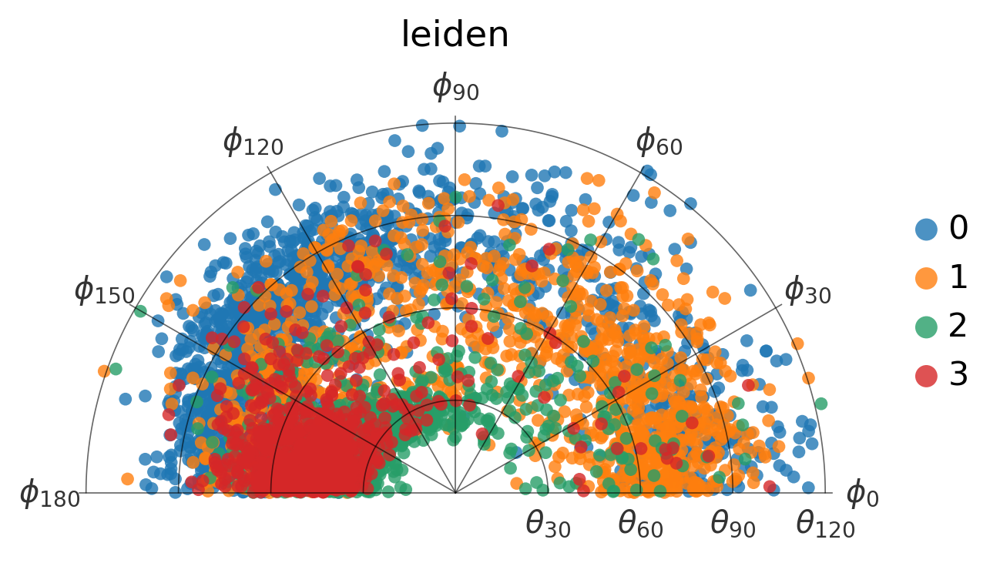

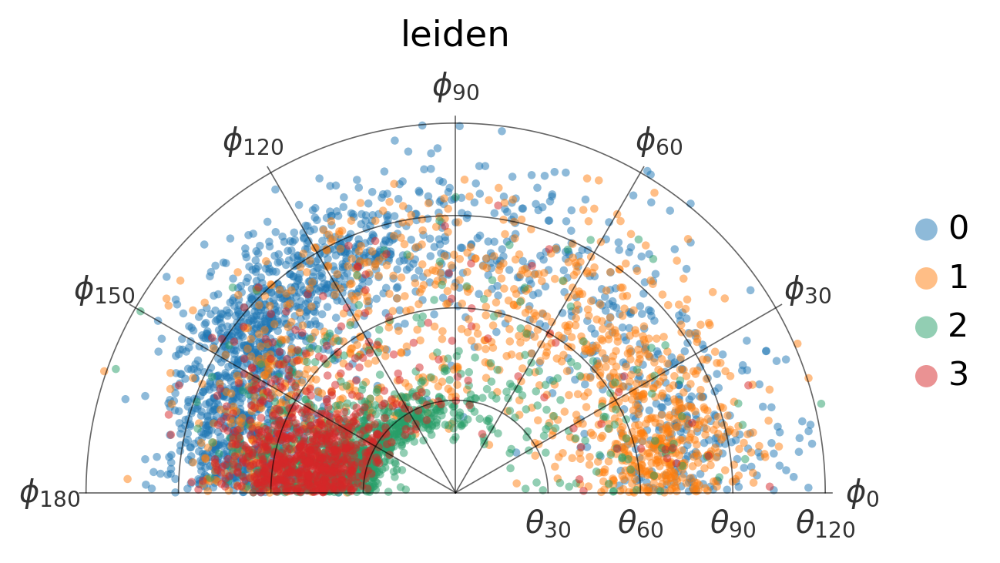

In [ ]:
colors=['leiden']
for color in colors:
  f = pl_scatter_polar(adata, color=color, half=True, phi='phi_folded', cmap='RdBu', size=100, label_kwargs={"fontsize": 12, "alpha": 0.8}, theta_label_gap=15)
  f.figure.savefig(base_path+'figs/polar/'+'YSL_mfProject_'+color+'.png', dpi=300, bbox_inches="tight")

colors=['leiden']
for color in colors:
  f = pl_scatter_polar(adata, color=color, half=True, phi='phi_folded', cmap='RdBu', size=40, alpha=0.5, label_kwargs={"fontsize": 12, "alpha": 0.8}, theta_label_gap=15, sort_order=False)
  f.figure.savefig(base_path+'figs/polar/'+'YSL_mfProject_'+color+'_s40.png', dpi=300, bbox_inches="tight")


In [ ]:
column = "leiden"
for category in adata.obs[column].dropna().unique():
    adata.obs[f"{column}_{category}"] = adata.obs[column].where(adata.obs[column] == category)

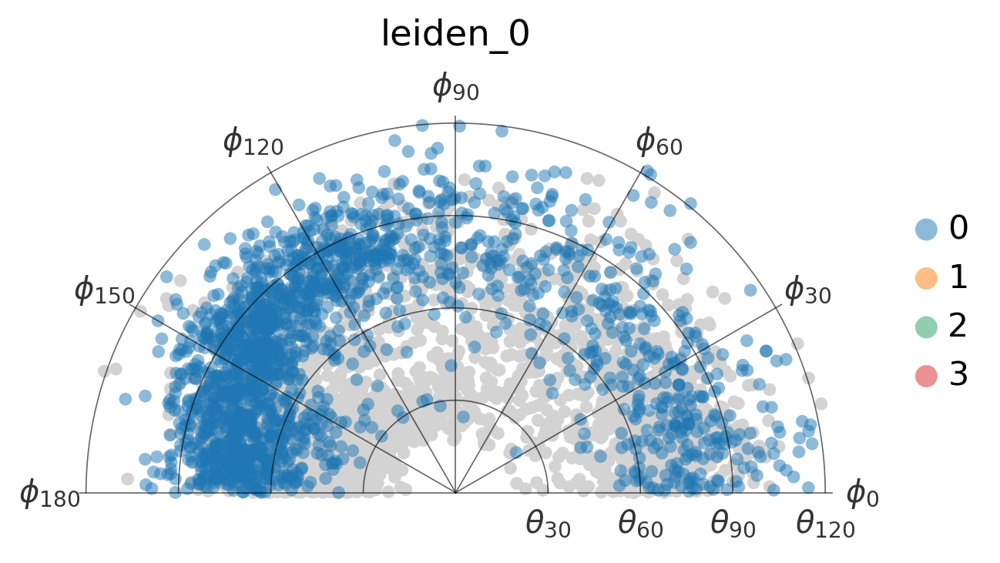

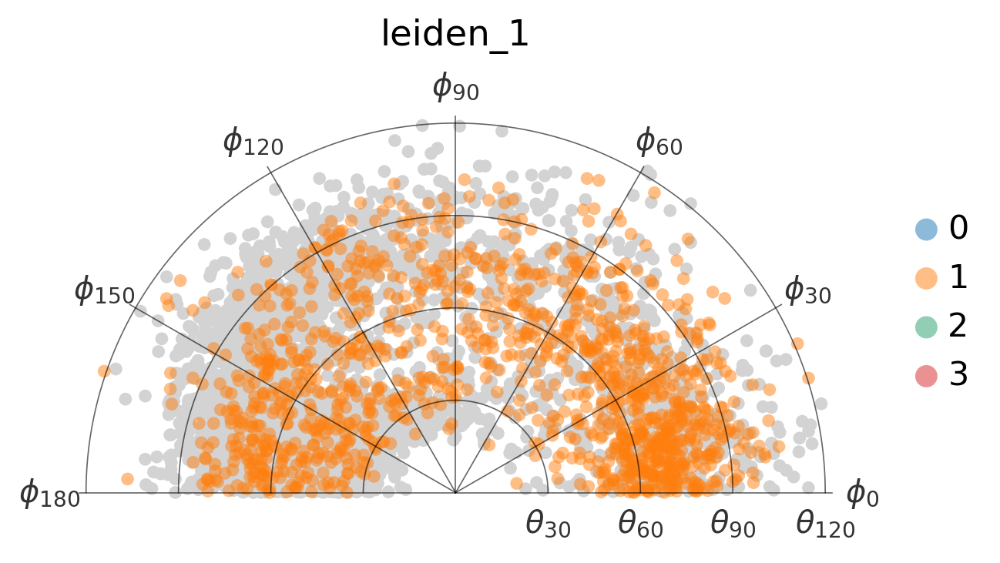

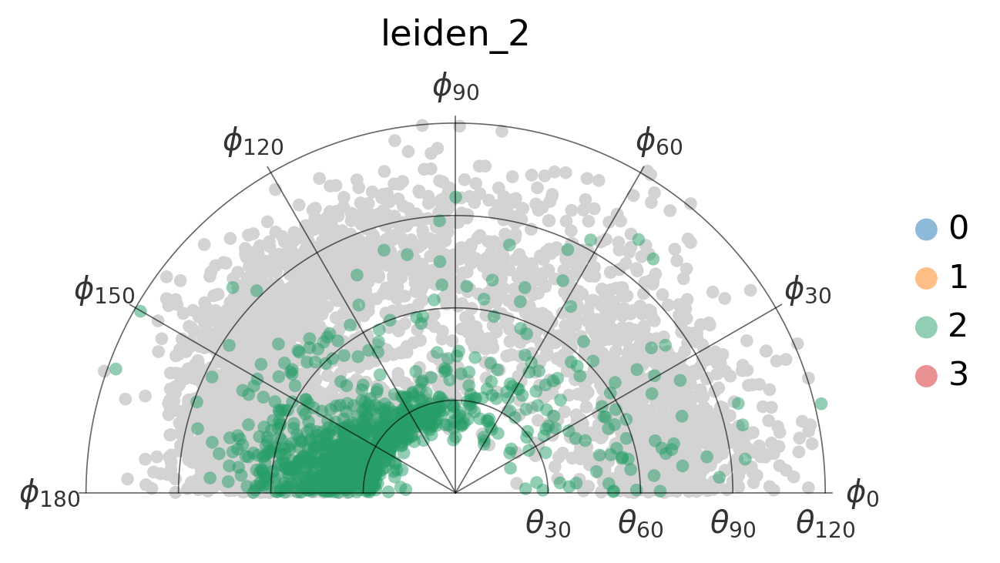

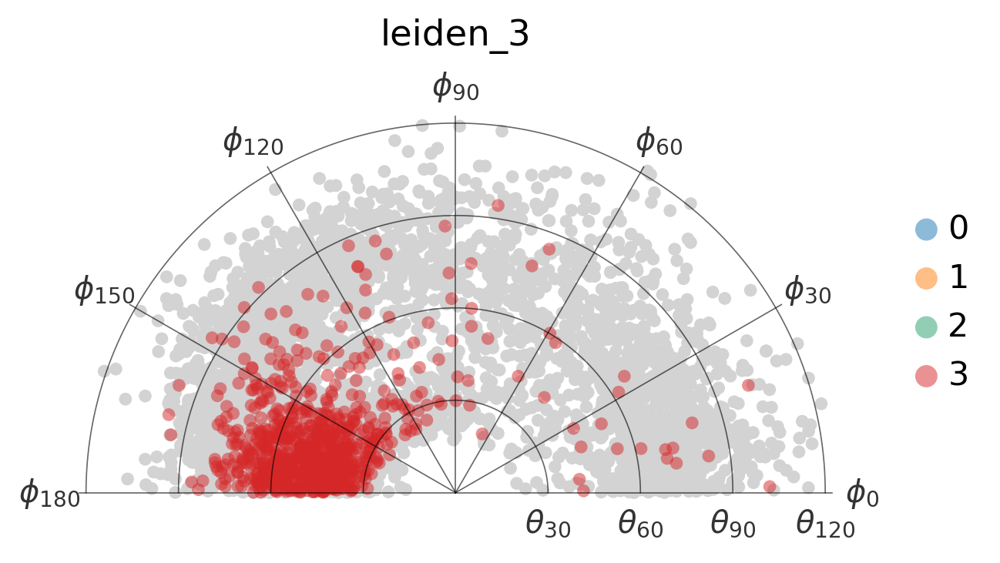

In [ ]:
colors=['leiden_0']
for color in colors:
  f = pl_scatter_polar(adata, color=color, half=True, phi='phi_folded', cmap='RdBu', size=100, alpha=0.5, label_kwargs={"fontsize": 12, "alpha": 0.8}, theta_label_gap=15)
  f.figure.savefig(base_path+'figs/polar/'+'YSL_mfProject_'+color+'.png', dpi=300, bbox_inches="tight")

colors=['leiden_1']
for color in colors:
  f = pl_scatter_polar(adata, color=color, half=True, phi='phi_folded', cmap='RdBu', size=100, alpha=0.5, label_kwargs={"fontsize": 12, "alpha": 0.8}, theta_label_gap=15)
  f.figure.savefig(base_path+'figs/polar/'+'YSL_mfProject_'+color+'.png', dpi=300, bbox_inches="tight")

colors=['leiden_2']
for color in colors:
  f = pl_scatter_polar(adata, color=color, half=True, phi='phi_folded', cmap='RdBu', size=100, alpha=0.5, label_kwargs={"fontsize": 12, "alpha": 0.8}, theta_label_gap=15)
  f.figure.savefig(base_path+'figs/polar/'+'YSL_mfProject_'+color+'.png', dpi=300, bbox_inches="tight")

colors=['leiden_3']
for color in colors:
  f = pl_scatter_polar(adata, color=color, half=True, phi='phi_folded', cmap='RdBu', size=100, alpha=0.5, label_kwargs={"fontsize": 12, "alpha": 0.8}, theta_label_gap=15)
  f.figure.savefig(base_path+'figs/polar/'+'YSL_mfProject_'+color+'.png', dpi=300, bbox_inches="tight")


In [ ]:
adata.obs.groupby("leiden")[["theta", "phi_folded"]].agg(["mean", "std"])

/tmp/ipykernel_266/343343912.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  adata.obs.groupby("leiden")[["theta", "phi_folded"]].agg(["mean", "std"])


theta             phi_folded           
             mean        std        mean        std
leiden                                             
0       79.413401  14.567044  119.330838  49.966091
1       67.147719  17.464156   78.693777  58.629184
2       41.821135  15.949820  136.141273  43.988048
3       52.612884  14.261503  155.975554  29.163574

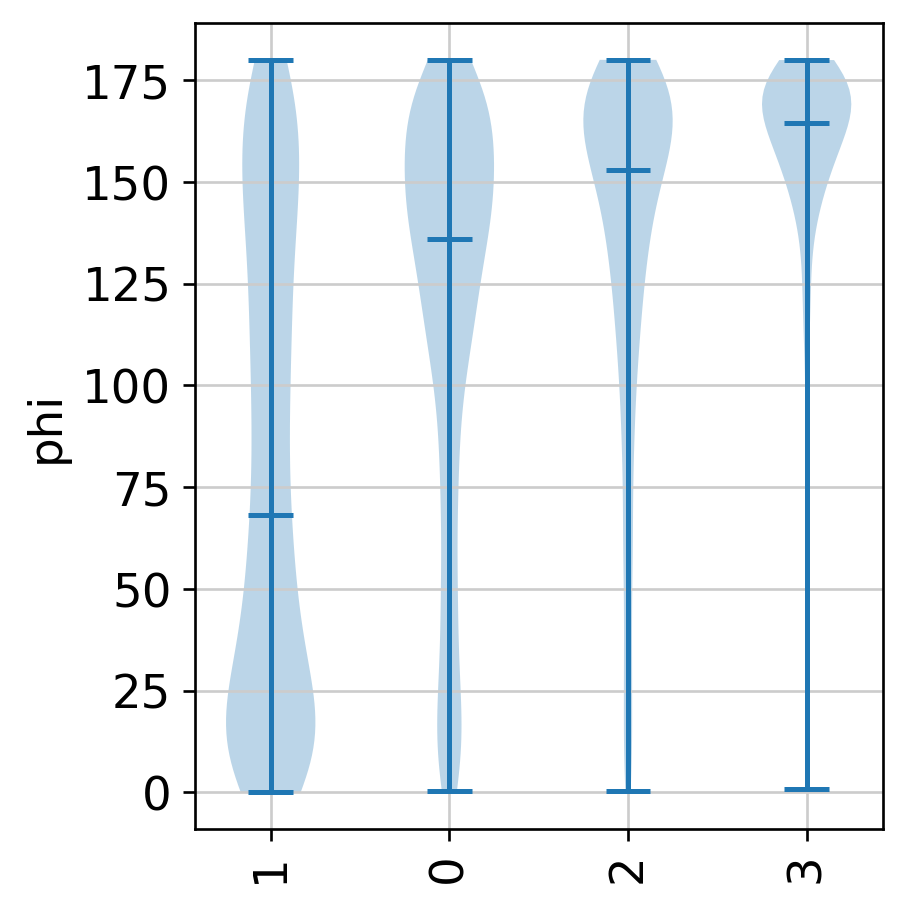

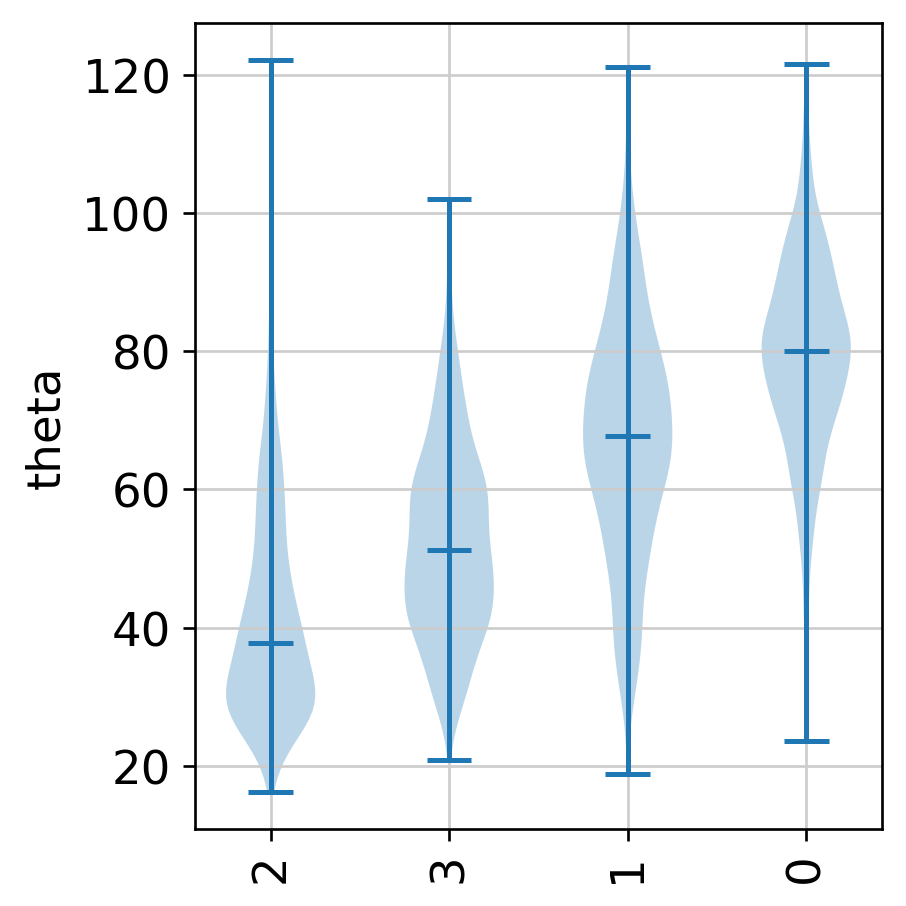

In [ ]:
def plot_spatial_violin(
    adata,
    cluster_col='clusters',
    spatial_col='phi',
    sort_by_median=False,
    #ylim=(0, 200),
    figsize=(4, 4),
):
    tissues = adata.obs[cluster_col].dropna().unique().tolist()

    if sort_by_median:
        tissues = sorted(
            tissues,
            key=lambda x: np.abs(
                adata.obs.loc[adata.obs[cluster_col] == x, spatial_col]
            ).median()
        )

    data = [
        np.abs(adata.obs.loc[adata.obs[cluster_col] == tissue, spatial_col].dropna())
        for tissue in tissues
    ]

    fig, ax = plt.subplots(figsize=figsize)

    ax.violinplot(data, showmedians=True)
    ax.set_xticks(range(1, len(tissues) + 1))
    ax.set_xticklabels(tissues, rotation=90)
    ax.set_ylabel(spatial_col)
    #ax.set_ylim(*ylim)

    plt.tight_layout()
    return fig, ax

f1,_ = plot_spatial_violin(adata, cluster_col='leiden', spatial_col='phi', sort_by_median=True)
f2,_ = plot_spatial_violin(adata, cluster_col='leiden', spatial_col='theta', sort_by_median=True)

f1.savefig(base_path+'figs/'+'merFISH_phi_vs_leiden.png', dpi=200, bbox_inches="tight")
f2.savefig(base_path+'figs/'+'merFISH_theta_vs_leiden.png', dpi=200, bbox_inches="tight")


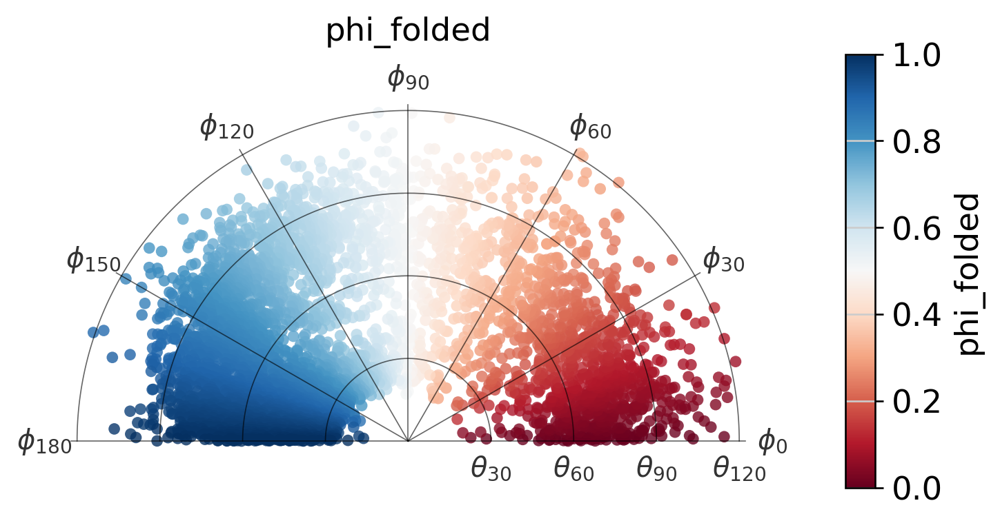

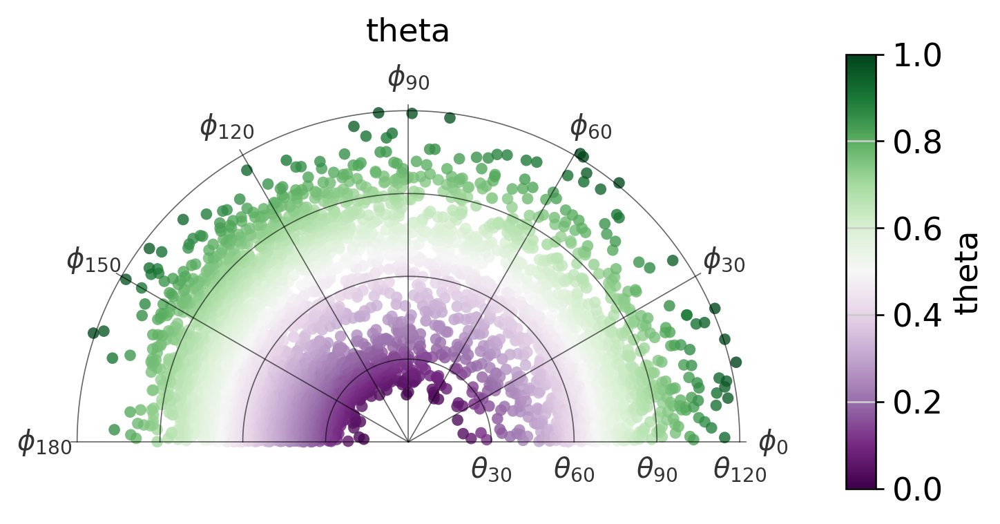

In [ ]:
colors=['phi_folded']
for color in colors:
  f = pl_scatter_polar(adata, color=color, half=True, phi='phi_folded', cmap='RdBu', size=25, label_kwargs={"fontsize": 12, "alpha": 0.8}, theta_label_gap=15)
  f.figure.savefig(base_path+'figs/polar/'+'YSL_mfProject_'+color+'.png', dpi=300, bbox_inches="tight")

colors=['theta']
for color in colors:
  f = pl_scatter_polar(adata, color=color, half=True, phi='phi_folded', cmap='PRGn', size=25, label_kwargs={"fontsize": 12, "alpha": 0.8}, theta_label_gap=15)
  f.figure.savefig(base_path+'figs/polar/'+'YSL_mfProject_'+color+'.png', dpi=300, bbox_inches="tight")



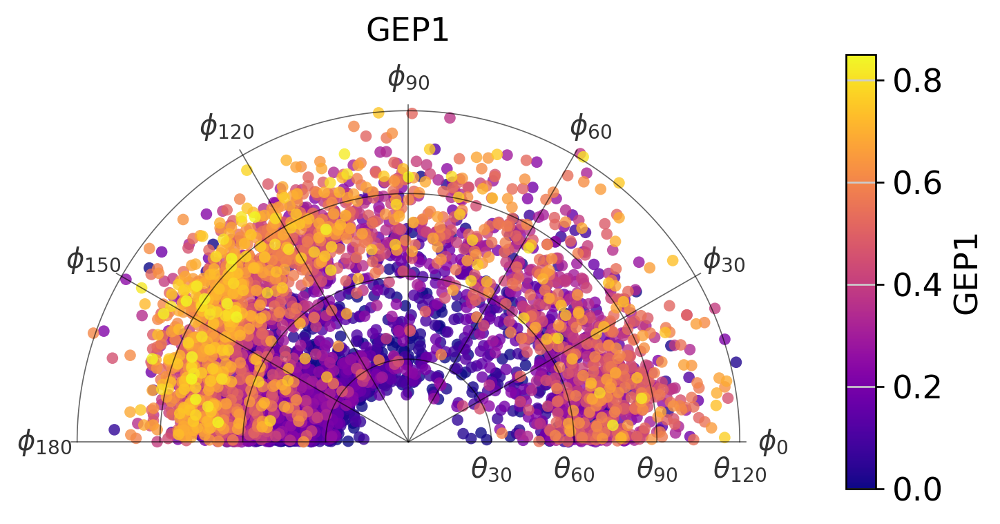

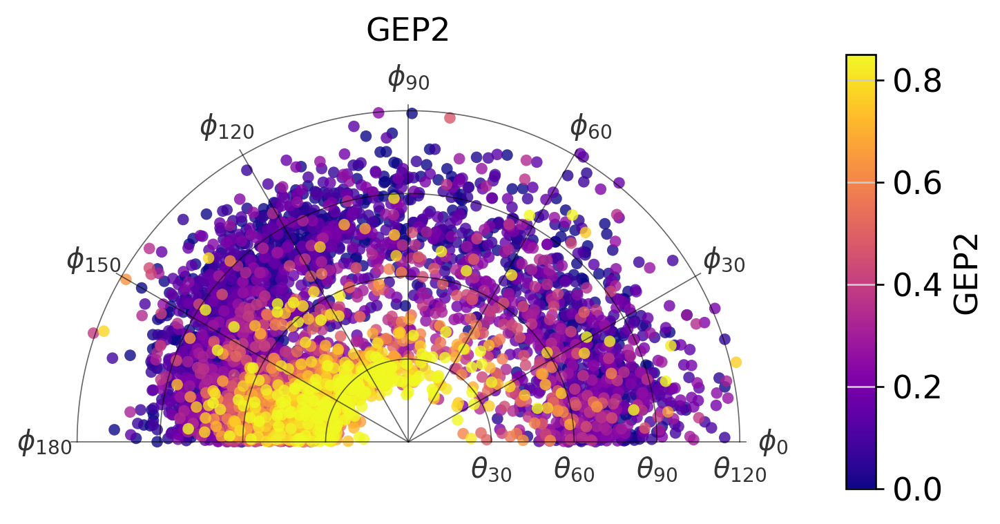

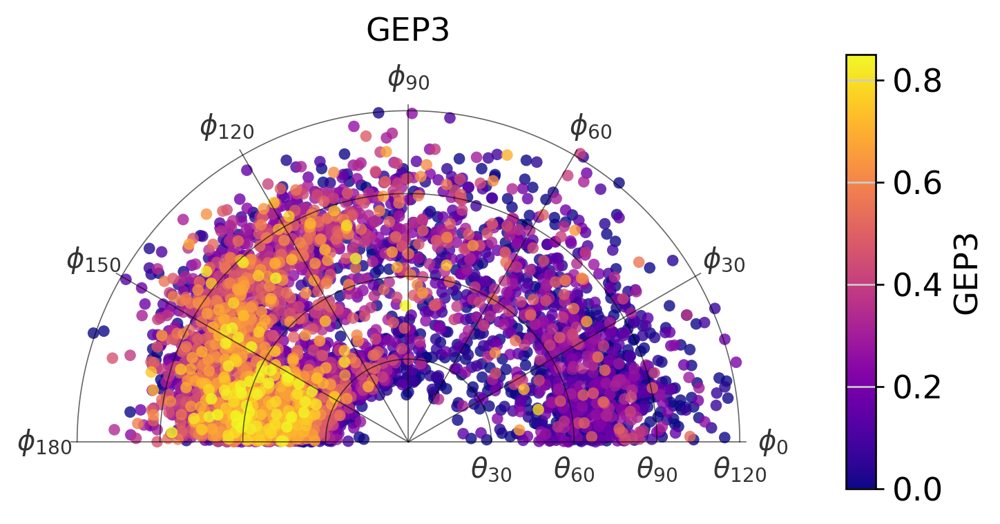

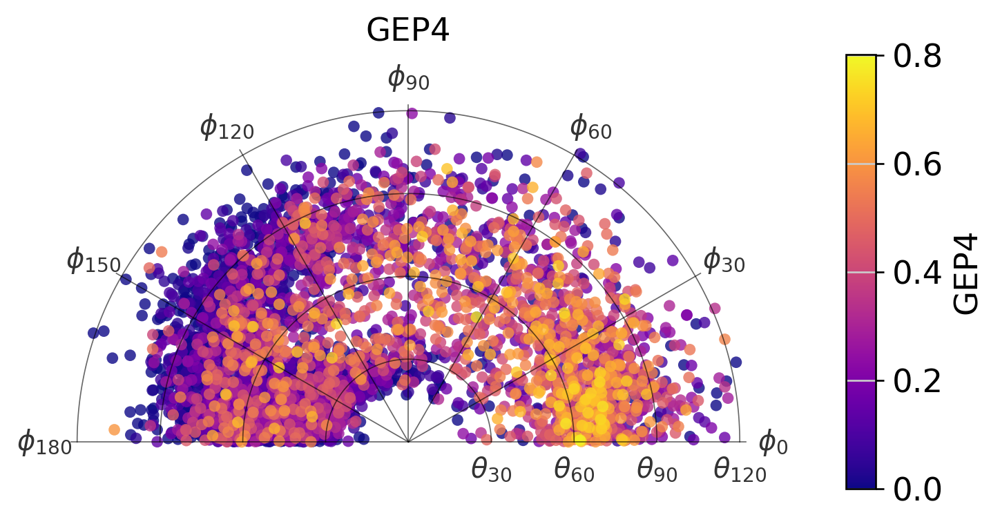

In [ ]:
colors=['GEP1', 'GEP2', 'GEP3', 'GEP4']
for color in colors:
  f = pl_scatter_polar(adata, color=color, half=True, phi='phi_folded', size=25, alpha=0.8, cmap='plasma', standard_scale=None, vmax=0.85, sort_order=True,label_kwargs={"fontsize": 12, "alpha": 0.8}, theta_label_gap=15)
  f.figure.savefig(base_path+'figs/polar/'+'YSL_mfProject_'+color+'.png', dpi=300, bbox_inches="tight")


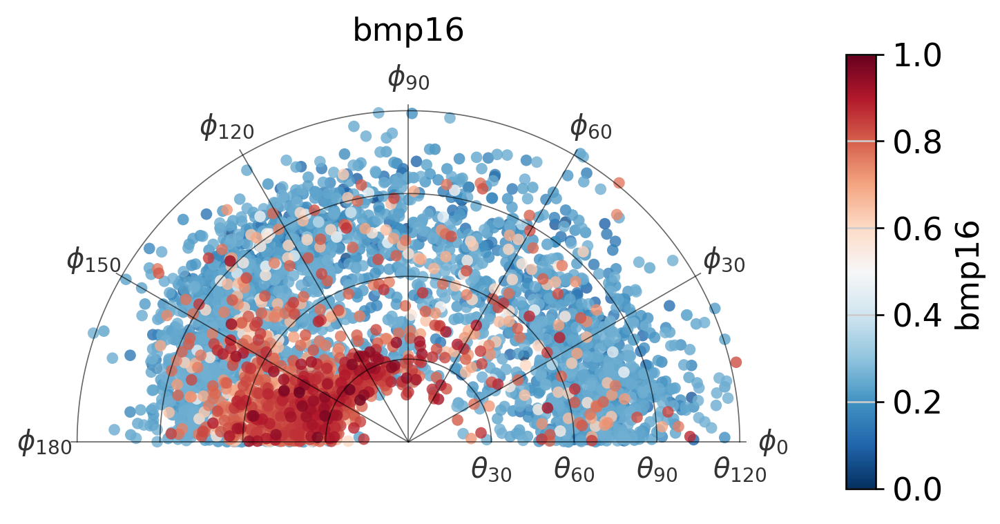

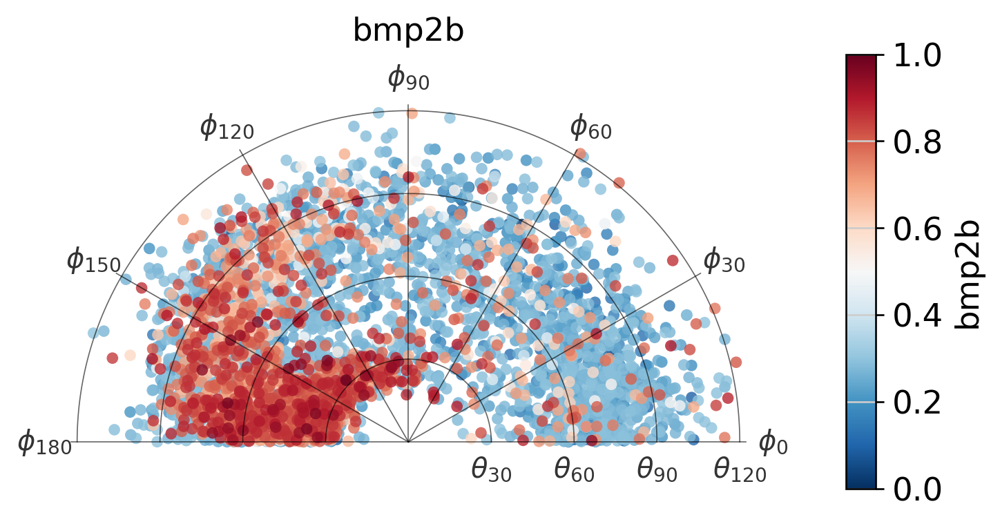

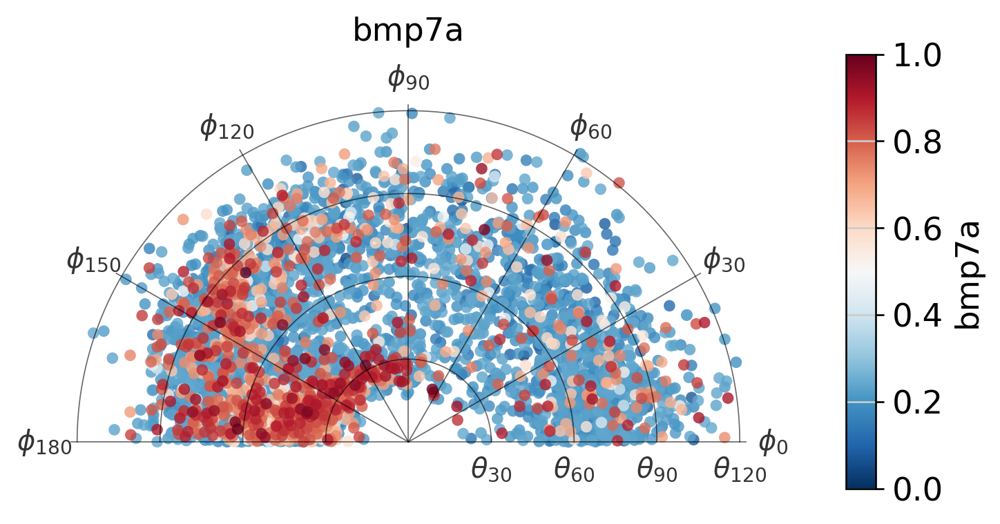

In [ ]:
colors=['bmp16','bmp2b','bmp7a']
for color in colors:
  f = pl_scatter_polar(adata, color=color, half=True, phi='phi_folded', label_kwargs={"fontsize": 12, "alpha": 0.8}, theta_label_gap=15)
  f.figure.savefig(base_path+'figs/polar/'+'YSL_mfProject_'+color+'.png', dpi=300, bbox_inches="tight")


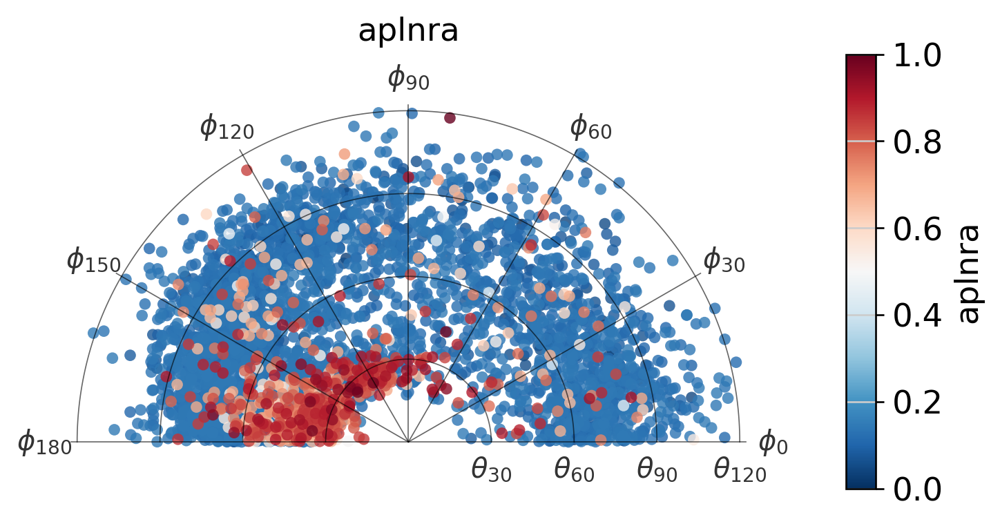

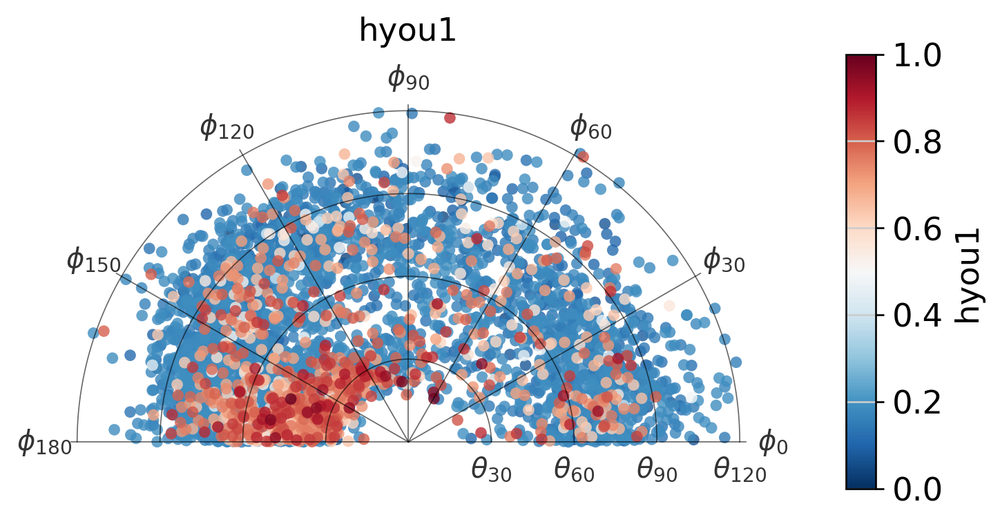

In [ ]:
colors=['aplnra','hyou1']
for color in colors:
  f = pl_scatter_polar(adata, color=color, half=True, phi='phi_folded', label_kwargs={"fontsize": 12, "alpha": 0.8}, theta_label_gap=15)
  f.figure.savefig(base_path+'figs/polar/'+'YSL_mfProject_'+color+'.png', dpi=300, bbox_inches="tight")


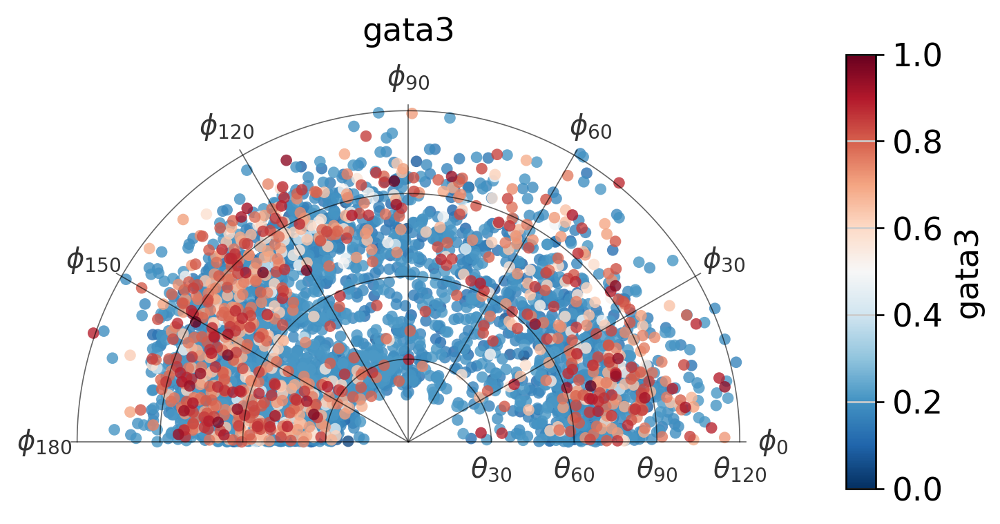

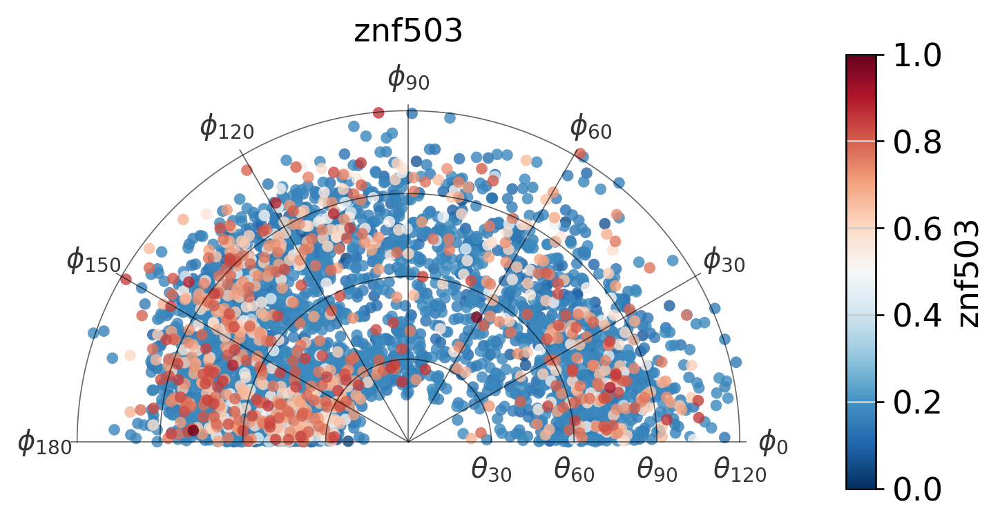

In [ ]:
colors=['gata3','znf503']
for color in colors:
  f = pl_scatter_polar(adata, color=color, half=True, phi='phi_folded', label_kwargs={"fontsize": 12, "alpha": 0.8}, theta_label_gap=15)
  f.figure.savefig(base_path+'figs/polar/'+'YSL_mfProject_'+color+'.png', dpi=300, bbox_inches="tight")


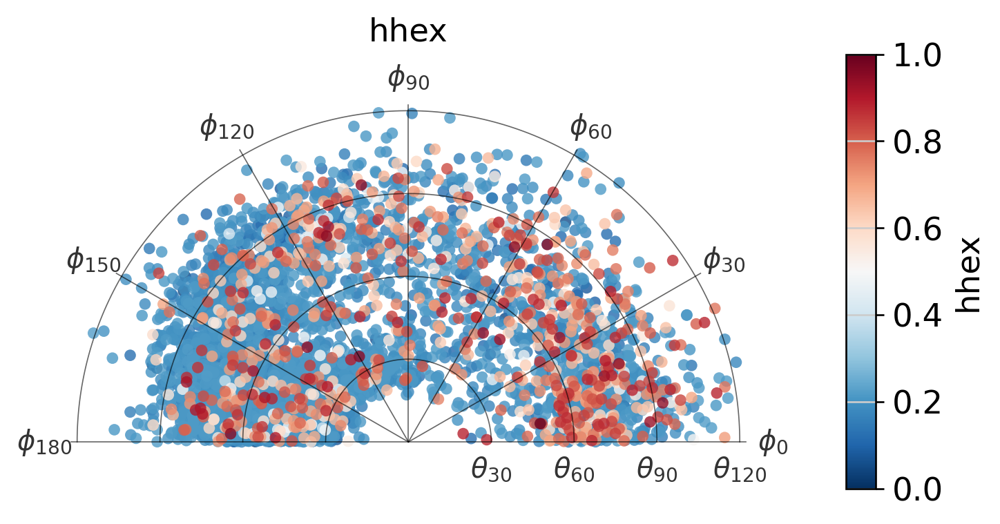

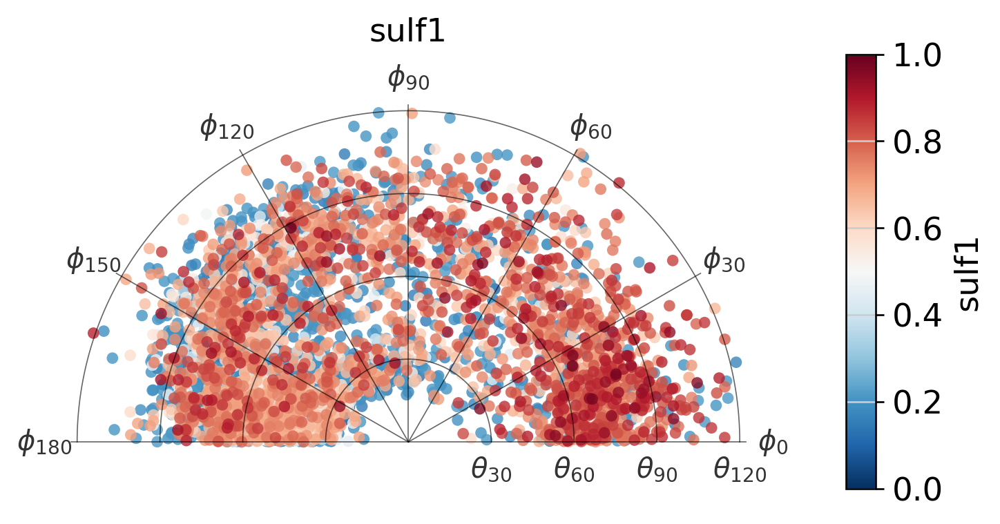

In [ ]:
colors=['hhex','sulf1']
for color in colors:
  f = pl_scatter_polar(adata, color=color, half=True, phi='phi_folded', label_kwargs={"fontsize": 12, "alpha": 0.8}, theta_label_gap=15)
  f.figure.savefig(base_path+'figs/polar/'+'YSL_mfProject_'+color+'.png', dpi=300, bbox_inches="tight")


In [ ]:
sc.tl.score_genes(adata, gene_list=['bmp16','bmp2b'], score_name='bmps')

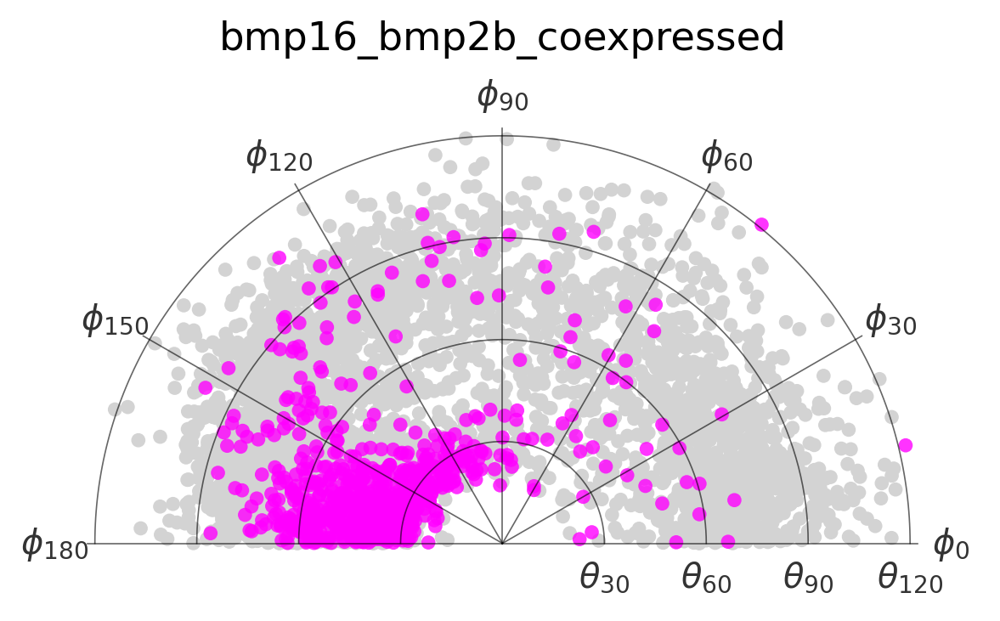

In [ ]:
colors=['bmp16_bmp2b_coexpressed']
for color in colors:
  f = pl_scatter_polar(adata, color=color, half=True, phi='phi_folded', size=100, groups='Coexpressed', palette=['magenta'], label_kwargs={"fontsize": 12, "alpha": 0.8}, theta_label_gap=15, legend_loc='none')
  f.figure.savefig(base_path+'figs/polar/'+'YSL_mfProject_'+color+'.png', dpi=300, bbox_inches="tight")
